# 01. Навчання U-Net для реставрації баркодів

**Ідея:** CNN не читає баркод, а реставрує кадр: зіпсований -> чистий. Читає звичайний декодер.

```
зіпсований кадр -> U-Net -> декодер (zxing-cpp / OpenCV) -> рядок
```

**Пари для навчання** будуємо самі: `ціль = чистий кадр`, `вхід = той самий кадр +
випадкове пошкодження` (dark, uneven, glare, noise, motion_blur, defocus, jpeg; рівні 1-5).
Частина пар без пошкодження, щоб мережа вчилась не псувати хороші кадри.

**Дві моделі, однакові налаштування, різні чисті кадри:**
- `synthetic`: лише згенеровані коди на білому фоні (для порівняння);
- `mix`: синтетика + реальні фото приблизно навпіл. **Це модель для лінії.**

**Реальні фото** (лише ті, що декодер читає на оригіналі, тобто достатньо чисті):
- Arte-Lab: EAN-13 на товарах (CC BY 3.0);
- ParcelBar: Code128 на посилках (CC BY-SA 4.0);
- InventBar: коди на складських коробках (CC BY-SA 4.0).

Кожен набір ділимо на train/test **за кодом**: той самий товар лише в одній частині.

**Швидкість:** мережа маленька (~1.9 млн параметрів), вчимо на шматках 128×128,
4000 кроків по 32 шматки. На Mac Mini M4 (MPS) ~10-12 хвилин на модель.

In [1]:
import sys
from pathlib import Path

# ноутбук лежить у notebooks/, корінь проєкту на рівень вище
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
from src.data import generate_synthetic, load_real_split, make_training_batch
from src.model import UNet, get_device

# Синтетика: train і test з різним seed (різні коди)
synthetic_train = generate_synthetic(n_per_format=300, seed=1)
synthetic_test = generate_synthetic(n_per_format=30, seed=2)

# Реальні фото трьох наборів, поділ за кодом у кожному наборі
real_train, real_test = load_real_split()

# Суміш: кадр для пари обирається випадково зі списку, тому реальні фото повторюємо,
# щоб їх було приблизно стільки ж, скільки синтетики (навпіл).
repeats = max(1, round(len(synthetic_train) / len(real_train)))
mix_train = synthetic_train + real_train * repeats

DATASETS = {
    "synthetic": (synthetic_train, synthetic_test),
    "mix": (mix_train, real_test),      # test = реальні фото: саме на них важливий результат
}
print("Реальних фото в train:", len(real_train), "| повторів у суміші:", repeats)
print("Спільних кодів train/test:", len(set(s["text"] for s in real_train) & set(s["text"] for s in real_test)))

artelab: 247 фото з відповіддю -> train 166, test 81
parcelbar: 183 фото з відповіддю -> train 128, test 55
inventbar: 416 фото з відповіддю -> train 291, test 125
Реальних фото в train: 585 | повторів у суміші: 2
Спільних кодів train/test: 0


## Як виглядають пари (вгорі вхід, внизу ціль)

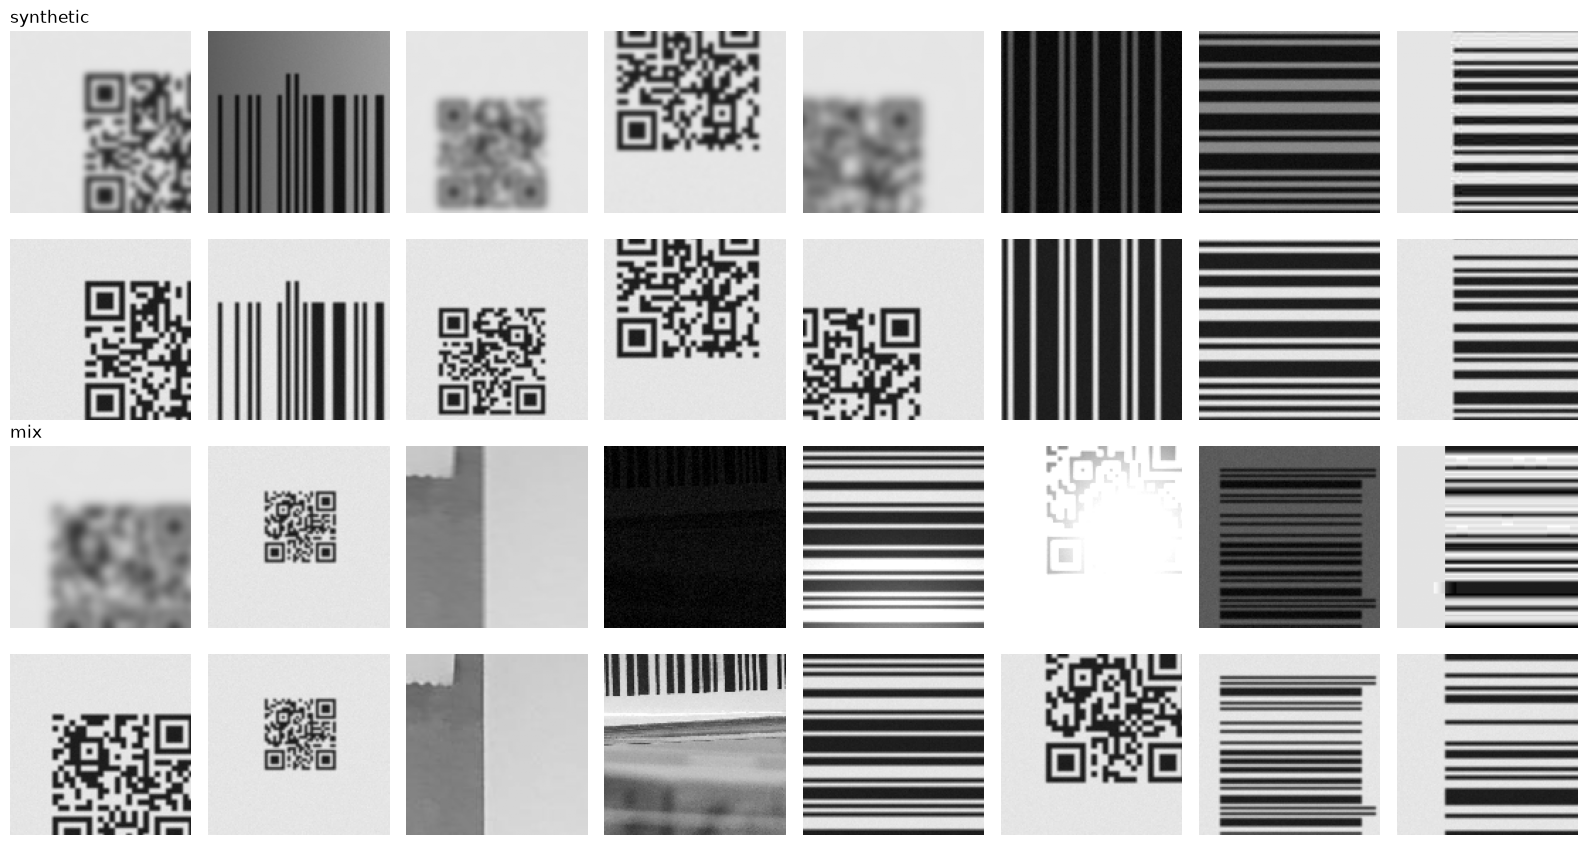

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for row, name in enumerate(DATASETS):
    inputs, targets = make_training_batch(DATASETS[name][0], 8, rng)
    for i in range(8):
        axes[row * 2, i].imshow(inputs[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[row * 2 + 1, i].imshow(targets[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[row * 2, 0].set_title(name, loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Архітектура U-Net

Вхід 1×128×128 (сірий шматок кадру). Encoder (`down`) чотири рази зменшує кадр удвічі
(128 -> 8) і збільшує кількість каналів (16 -> 256). Decoder (`up`, `up_blocks`) повертає
розмір назад до 128×128. Найбільше параметрів у `bottom`, де 256 каналів.

In [4]:
from torchinfo import summary

# таблиця шарів, як model.summary() у Keras: розмір виходу і кількість параметрів
summary(UNet(), input_size=(1, 1, 128, 128), depth=2,
        col_names=["output_size", "num_params"], row_settings=["var_names"])

Layer (type (var_name))                  Output Shape              Param #
UNet (UNet)                              [1, 1, 128, 128]          --
├─ModuleList (down)                      --                        (recursive)
│    └─Sequential (0)                    [1, 16, 128, 128]         2,544
├─MaxPool2d (pool)                       [1, 16, 64, 64]           --
├─ModuleList (down)                      --                        (recursive)
│    └─Sequential (1)                    [1, 32, 64, 64]           14,016
├─MaxPool2d (pool)                       [1, 32, 32, 32]           --
├─ModuleList (down)                      --                        (recursive)
│    └─Sequential (2)                    [1, 64, 32, 32]           55,680
├─MaxPool2d (pool)                       [1, 64, 16, 16]           --
├─ModuleList (down)                      --                        (recursive)
│    └─Sequential (3)                    [1, 128, 16, 16]          221,952
├─MaxPool2d (pool)               

## Навчання

- **Loss L1** = середня різниця яскравості між виходом мережі і чистим кадром.
- **Adam** змінює ваги так, щоб loss зменшувався.
- **Cosine schedule**: крок навчання (learning rate) плавно зменшується до кінця.
- **Validation loss** рахуємо кожні 500 кроків на test-кадрах, яких мережа не бачить.
  Якщо train loss падає, а validation росте, мережа запам'ятовує train (overfitting).
  Accuracy тут немає (мережа не класифікує), її роль грає decode rate у 02_evaluate.

In [5]:
STEPS = 4000
BATCH = 32
device = get_device()
loss_fn = torch.nn.L1Loss()


@torch.no_grad()
def validation_loss(model, test_part):
    """L1 на 8 фіксованих пачках з test (той самий rng щоразу -> чесне порівняння)."""
    model.eval()
    rng = np.random.default_rng(123)
    values = []
    for _ in range(8):
        inputs, targets = make_training_batch(test_part, BATCH, rng)
        outputs = model(torch.from_numpy(inputs).to(device))
        values.append(loss_fn(outputs, torch.from_numpy(targets).to(device)).item())
    model.train()
    return np.mean(values)


history = {}
for name, (train_part, test_part) in DATASETS.items():
    torch.manual_seed(0)
    model = UNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STEPS)
    rng = np.random.default_rng(1)
    losses, val_losses = [], []
    start = time.time()
    model.train()
    for step in range(1, STEPS + 1):
        inputs, targets = make_training_batch(train_part, BATCH, rng)
        loss = loss_fn(model(torch.from_numpy(inputs).to(device)),
                       torch.from_numpy(targets).to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        if step % 500 == 0:
            val_losses.append((step, validation_loss(model, test_part)))
            print(f"{name} крок {step}: train {np.mean(losses[-500:]):.4f}, "
                  f"validation {val_losses[-1][1]:.4f}, {time.time() - start:.0f} с")
    torch.save(model.state_dict(), MODELS / f"unet_{name}.pt")
    history[name] = (losses, val_losses)
    print("Збережено:", MODELS / f"unet_{name}.pt")

# криві для презентації: train (середнє по 500 крокам) і validation кожні 500 кроків
rows = []
for name, (losses, val_losses) in history.items():
    for step, value in val_losses:
        rows.append({"model": name, "step": step,
                     "train": np.mean(losses[step - 500:step]), "validation": value})
pd.DataFrame(rows).to_csv(RESULTS / "training_history.csv", index=False)

synthetic крок 500: train 0.0598, validation 0.0327, 82 с
synthetic крок 1000: train 0.0339, validation 0.0264, 165 с
synthetic крок 1500: train 0.0309, validation 0.0238, 248 с
synthetic крок 2000: train 0.0272, validation 0.0209, 330 с
synthetic крок 2500: train 0.0239, validation 0.0200, 414 с
synthetic крок 3000: train 0.0218, validation 0.0186, 497 с
synthetic крок 3500: train 0.0205, validation 0.0180, 580 с
synthetic крок 4000: train 0.0197, validation 0.0179, 663 с
Збережено: /Users/andriizemlianyi/Code/zemand-learning/Computer Vision/r_d/r_d-computer-vision-project/models/unet_synthetic.pt
mix крок 500: train 0.0998, validation 0.0838, 91 с
mix крок 1000: train 0.0782, validation 0.0827, 183 с
mix крок 1500: train 0.0722, validation 0.0754, 275 с
mix крок 2000: train 0.0662, validation 0.0722, 367 с
mix крок 2500: train 0.0630, validation 0.0685, 459 с
mix крок 3000: train 0.0612, validation 0.0664, 551 с
mix крок 3500: train 0.0584, validation 0.0583, 643 с
mix крок 4000: tra

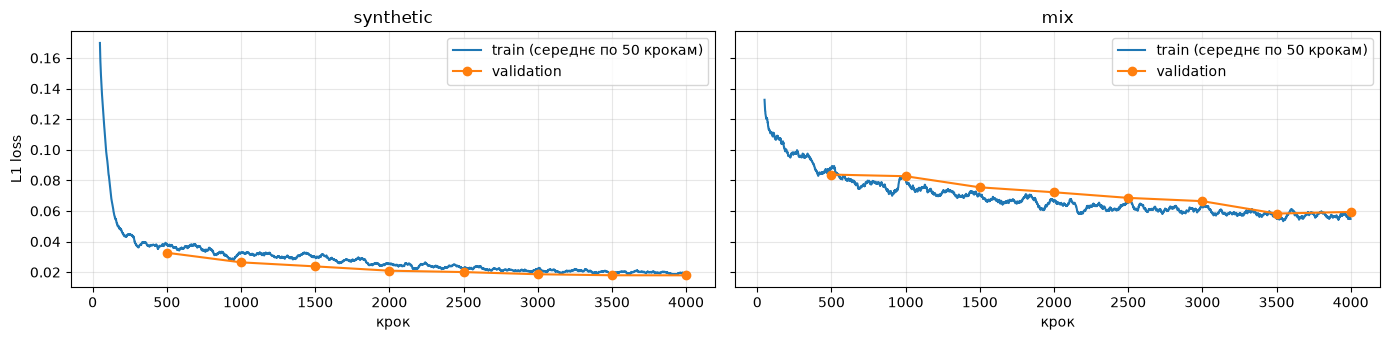

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, (name, (losses, val_losses)) in zip(axes, history.items()):
    ax.plot(pd.Series(losses).rolling(50).mean(), label="train (середнє по 50 крокам)")
    steps, values = zip(*val_losses)
    ax.plot(steps, values, "o-", label="validation")
    ax.set_title(name)
    ax.set_xlabel("крок")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("L1 loss")
plt.tight_layout()
plt.savefig(RESULTS / "fig_training.png", dpi=100)
plt.show()